# Assignment 10 - From Images to Short Textual Descriptions
### A Vision Transformer from Scratch with Qwen2.5-0.5B-Instruct

**Duration:** 3 hours  |  **Maximum marks:** 50  |  **Seed:** 42

**Student notebook :- complete the `TODO` sections.** Read the supplied assignment PDF for the full instructions and marking policy. This notebook provides imports, paths, configuration, and task cells **without assessed implementations**.

**System:** `image → your ViT → top-two class evidence → frozen text-only Qwen → one-sentence description`. Qwen does **not** see image pixels. Do not claim to identify colours, actions, counts, or backgrounds from class predictions.

## Before starting

Extract the supplied data/model archives such that the structure, relative to the folder containing this notebook, is:

```text
Assignment_10/
├── Assignment_10_Starter.ipynb
├── data/
│   └── cifar10_lab.npz
└── models/
    └── Qwen2.5-0.5B-Instruct/
        ├── config.json
        ├── model.safetensors
        └── ... (tokenizer and other model files)
```

**Rules:** Work completely offline. No model downloads, internet, pretrained ViT, `nn.MultiheadAttention`, `nn.TransformerEncoder`, `nn.TransformerEncoderLayer`, or ready-made attention functions. Train **only** the ViT; Qwen remains frozen. Keep the provided data split and test order.

Run cells in order. If an extraction created an extra nested directory, move the extracted directory to match the paths above.

In [89]:
# Common imports (provided; not graded)
import os
import time
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForCausalLM

# Do not permit remote Hugging Face retrievals.
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ROOT = Path.cwd()  # Open/run this notebook from the Assignment_10 folder.
DATA_PATH = ROOT / "data" / "cifar10_lab.npz"
MODEL_PATH = ROOT / "models" / "Qwen2.5-0.5B-Instruct"
OUTPUT_DIR = ROOT

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Tested-setting convention for this lab: FP16 on CUDA, FP32 otherwise.
QWEN_DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32

IMAGE_SIZE = 32
IN_CHANNELS = 3
PATCH_SIZE = 4
EMBED_DIM = 64
NUM_BLOCKS = 2
NUM_HEADS = 4
MLP_DIM = 128
NUM_CLASSES = 10
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 5
TRAINING_TIME_LIMIT_SECONDS = 12 * 60
GRAD_CLIP_NORM = 1.0
DROPOUT = 0.0

print("Python seed:", SEED)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", DEVICE)
print("Qwen dtype:", QWEN_DTYPE)
print("Data exists:", DATA_PATH.is_file(), "→", DATA_PATH)
print("Qwen config exists:", (MODEL_PATH / "config.json").is_file(), "→", MODEL_PATH)
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset missing: {DATA_PATH}. Check ZIP extraction/folder names.")
if not (MODEL_PATH / "config.json").is_file():
    raise FileNotFoundError(f"Qwen model missing: {MODEL_PATH}. Check ZIP extraction/folder names.")

Python seed: 42
PyTorch: 2.8.0+cu128
CUDA available: True
Device: cuda
Qwen dtype: torch.float16
Data exists: True → /home/user/24AI10013_Assgn10/Assignment10/data/cifar10_lab.npz
Qwen config exists: True → /home/user/24AI10013_Assgn10/Assignment10/models/Qwen2.5-0.5B-Instruct


## Question 1 - Dataset Inspection and Input Pipeline (10 marks)
### Task 1.1 - Inspect the supplied splits (4 marks)
Load the seven arrays from `cifar10_lab.npz`. Print each split's shape, min/max pixel range, and counts for each class. Verify **10,000 training**, **1,000 validation**, and **1,000 test** images. **Do not change the splits.**

In [67]:
print(DATA_PATH)

/home/user/24AI10013_Assgn10/Assignment10/data/cifar10_lab.npz


In [68]:
# Task 1.1 - TODO (4 marks)
# Load x_train, y_train, x_val, y_val, x_test, y_test, class_names.
# Print shapes, pixel ranges, class counts, and verify required sizes.
data = np.load(DATA_PATH, mmap_mode="r")
x_train, y_train, x_val, y_val, x_test, y_test, class_names = data['x_train'], data['y_train'], data['x_val'], data['y_val'], data['x_test'], data['y_test'], data['class_names']

In [69]:
x_train.shape, y_train.shape, x_val.shape, y_val.shape, x_test.shape, y_test.shape, class_names.shape

((10000, 32, 32, 3),
 (10000,),
 (1000, 32, 32, 3),
 (1000,),
 (1000, 32, 32, 3),
 (1000,),
 (10,))

In [169]:
print(class_names)

['airplane' 'automobile' 'bird' 'cat' 'deer' 'dog' 'frog' 'horse' 'ship'
 'truck']


In [70]:
np.bincount(y_train), np.bincount(y_val), np.bincount(y_test)

(array([1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]),
 array([100, 100, 100, 100, 100, 100, 100, 100, 100, 100]),
 array([100, 100, 100, 100, 100, 100, 100, 100, 100, 100]))

In [71]:
np.max(x_train[0]), np.min(x_train[0])

(237, 11)

In [72]:
x_train.dtype

dtype('uint8')

In [73]:
x = x_train.transpose(0, 3, 1, 2).astype(np.float32)
x = 2 * (x / 255.0) - 1
print(x.shape)
print(x.dtype)

(10000, 3, 32, 32)
float32


### Task 1.2 -  Prepare tensors and verify a batch (6 marks)

Create a PyTorch `Dataset` and three `DataLoader`s. Convert images from `(32, 32, 3)` `uint8` to `(3, 32, 32)` `float32`; normalize with **`x_normalized = 2 * (x / 255) - 1`**. Use integer (`long`) class labels for cross-entropy. Shuffle **training only** and use **`num_workers=0`**. Print one batch's shapes and display **four training images** with class names after reversing normalization. No augmentation.

In [74]:
# Task 1.2 - TODO (6 marks)
# Define your Dataset and train/val/test DataLoaders.
# Check batch shapes and display four denormalized training images.
class MyDataset(Dataset):
    def __init__(self, x, y):
        super().__init__()
        self.x = x
        self.y = y
        assert self.x.shape[0] == self.y.shape[0] 
    def __len__(self):
        return self.x.shape[0]
    def __getitem__(self, idx):
        x_item, y_item = self.x[idx], self.y[idx]
        x = x_item.transpose(2, 0, 1).astype(np.float32)
        x = 2 * (x / 255.0) - 1
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y_item, dtype=torch.long)

train_dataset = MyDataset(x_train, y_train)
val_dataset = MyDataset(x_val, y_val)
test_dataset = MyDataset(x_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, num_workers=0, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, num_workers=0, shuffle=False)
print(len(train_loader), len(val_loader), len(test_loader))
print(len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))


79 8 8
10000 1000 1000


## Question 2 - Vision Transformer from Scratch (15 marks)

**Required architecture:** 4×4 non-overlapping patches; 64-dimensional embeddings; a learnable `[CLS]` token; learnable positional embeddings; **two pre-normalization** encoder blocks; four attention heads; `64 → 128 → 64` GELU MLP; final LayerNorm and linear 10-class head. Random initialization, dropout 0. Implement attention using elementary PyTorch ops (`nn.Linear`, tensor multiplication, `torch.softmax` etc.), **not** ready-made attention functions.

### Task 2.1 - Patch embedding and positional information (4 marks)

Implement `PatchEmbedding`. Either use `nn.Conv2d(3,64,kernel_size=4,stride=4)` then flatten/transposition, or extract patches and project with a linear layer. Compute `N`, print patch token shape, prepend the learned class token and add learned positional embeddings of shape `(1, N+1, 64)`. Print the resulting sequence shape for **two** dummy images. Explain positional embeddings in one sentence.

Hint for your shape check: 32/4 = 8 patches per side, so `N = 64` and the sequence contains 65 tokens including `[CLS]`.

In [77]:
# Task 2.1 - TODO (4 marks)
class PatchEmbedding(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO
        self.num_patches = (IMAGE_SIZE // PATCH_SIZE) ** 2
        self.proj = nn.Conv2d(IN_CHANNELS, EMBED_DIM, kernel_size=PATCH_SIZE, stride=PATCH_SIZE)
        self.cls = nn.Parameter(torch.zeros(EMBED_DIM, dtype=torch.float32), requires_grad=True)

    def forward(self, images):
        # TODO
        proj = self.proj(images).flatten(2).transpose(1, 2)
        # print(proj.shape)
        batch_size=proj.shape[0]
        return torch.cat((torch.repeat_interleave(self.cls[None, None], repeats=batch_size).reshape(batch_size, 1, EMBED_DIM), proj), dim=1)
# TODO: create and add CLS token/positional embedding (in your ViT or helper module).
# TODO: dummy batch shape demonstration.
img = torch.rand(2, 3, 32, 32)
layer = PatchEmbedding()
out = layer(img)
N = 64
print(out.shape)

torch.Size([2, 65, 64])


**Task 2.1 written answer - why positional embeddings are needed:**

> TODO

### Task 2.2 - Multi-head self-attention (7 marks)

Implement trainable `Q`, `K`, `V`, and output projections (one fused QKV projection is allowed). Split into `h=4` heads with `d_h=16`. Use **full bidirectional attention**, with no causal mask:

\[
A_j=\operatorname{softmax}\left(
rac{Q_jK_j^	op}{\sqrt{d_h}}
ight),\qquad H_j=A_jV_j.
\]

Concatenate head outputs and apply the final projection. Show the shapes of **Q**, the **attention matrix**, and the **output** for a dummy batch. Check that attention rows sum to approximately one.

In [78]:
# Task 2.2 - TODO (7 marks)
import math
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, dim=EMBED_DIM, num_heads=NUM_HEADS, debug=False):
        super().__init__()
        # TODO: projection layers and head metadata
        self.dim = dim
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.q_proj, self.k_proj, self.v_proj = nn.Linear(dim, dim), nn.Linear(dim, dim),nn.Linear(dim, dim)
        self.out_proj = nn.Linear(dim, dim)
        self.debug = debug

    def _split_heads(self, x):
        B, T, _ = x.shape
        x = x.view(B, T, self.num_heads, self.head_dim)
        return x.transpose(1, 2)
    
    def _merge_heads(self, x: torch.Tensor):
        b, h, t, d = x.shape
        x = x.transpose(1, 2).contiguous()
        return x.view(b, t, h*d)

    def forward(self, x: torch.Tensor):
        # TODO: Q/K/V, head reshape, scaled dot products, softmax, aggregation, output
        q, k, v = self.q_proj(x), self.k_proj(x), self.v_proj(x)
        if self.debug:
            print(f"Before splitting: q: {q.shape}, k: {k.shape}, v: {v.shape}")
        q, k, v = self._split_heads(q), self._split_heads(k), self._split_heads(v)
        if self.debug:
            print(f"After splitting: q: {q.shape}, k: {k.shape}, v: {v.shape}")
        scores = torch.matmul(q, k.transpose(-2, -1))
        scores = scores / math.sqrt(self.head_dim)
        attn_weights = torch.softmax(scores, dim=-1)
        if self.debug:
            print(f"Shape of attention weights: {attn_weights.shape}")
            print(f"min row sum: {torch.min(torch.sum(attn_weights, dim = -1))}, max row sum: {torch.max(torch.sum(attn_weights, dim = -1))}")
        x = torch.matmul(attn_weights, v)
        x = self._merge_heads(x)
        x = self.out_proj(x)
        if self.debug:
            print(f"final shape: {x.shape}")
        return x
# TODO: print Q/attention/output shapes and verify attention row sums.
mha_layer = MultiHeadSelfAttention(debug=True)
mha_layer(out)

Before splitting: q: torch.Size([2, 65, 64]), k: torch.Size([2, 65, 64]), v: torch.Size([2, 65, 64])
After splitting: q: torch.Size([2, 4, 65, 16]), k: torch.Size([2, 4, 65, 16]), v: torch.Size([2, 4, 65, 16])
Shape of attention weights: torch.Size([2, 4, 65, 65])
min row sum: 0.9999997615814209, max row sum: 1.000000238418579
final shape: torch.Size([2, 65, 64])


tensor([[[ 0.1596, -0.2444,  0.3176,  ..., -0.0065, -0.0888, -0.1255],
         [ 0.1593, -0.2448,  0.3176,  ..., -0.0066, -0.0888, -0.1258],
         [ 0.1594, -0.2449,  0.3178,  ..., -0.0068, -0.0888, -0.1258],
         ...,
         [ 0.1591, -0.2448,  0.3179,  ..., -0.0067, -0.0888, -0.1259],
         [ 0.1594, -0.2448,  0.3178,  ..., -0.0068, -0.0889, -0.1257],
         [ 0.1594, -0.2450,  0.3180,  ..., -0.0066, -0.0888, -0.1259]],

        [[ 0.1710, -0.2431,  0.3183,  ..., -0.0288, -0.0921, -0.1150],
         [ 0.1706, -0.2435,  0.3180,  ..., -0.0291, -0.0919, -0.1151],
         [ 0.1708, -0.2437,  0.3181,  ..., -0.0291, -0.0922, -0.1152],
         ...,
         [ 0.1707, -0.2434,  0.3183,  ..., -0.0290, -0.0919, -0.1151],
         [ 0.1706, -0.2435,  0.3180,  ..., -0.0290, -0.0919, -0.1150],
         [ 0.1706, -0.2434,  0.3183,  ..., -0.0291, -0.0920, -0.1150]]],
       grad_fn=<ViewBackward0>)

### Task 2.3 - Encoder blocks and classification head (4 marks)

Use separate normalization layers and residual connections:

\[
U=X+\operatorname{MSA}(\operatorname{LN}_1(X)),\qquad
Y=U+\operatorname{MLP}(\operatorname{LN}_2(U)).
\]

The MLP is `Linear(64,128) → GELU → Linear(128,64)`. Stack two blocks. Apply final LayerNorm, select the CLS token and return class logits through `Linear(64,10)` (**no softmax before cross-entropy**). Print number of trainable parameters and check output shape `(2,10)`.

In [79]:
# Task 2.3 - TODO (4 marks)
class EncoderBlock(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO
        self.ln1 = nn.LayerNorm(EMBED_DIM)
        self.ln2 = nn.LayerNorm(EMBED_DIM)
        self.msa = MultiHeadSelfAttention(debug=False)
        self.mlp = nn.Sequential(nn.Linear(EMBED_DIM, MLP_DIM), nn.GELU(), nn.Linear(MLP_DIM, EMBED_DIM))
    def forward(self, x):
        # TODO
        u = x + self.msa(self.ln1(x))
        return u + self.mlp(self.ln2(u))
    
class TinyViT(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: patch embed, CLS token, positional embedding, two blocks, final norm, head
        self.patch = PatchEmbedding()
        self.blocks = nn.Sequential(EncoderBlock(), EncoderBlock())
        self.ln = nn.LayerNorm(EMBED_DIM)
        self.classify = nn.Linear(EMBED_DIM, NUM_CLASSES)

    def forward(self, images):
        # TODO: return logits of shape (B, 10)
        x = self.patch(images) # b, 65, 64
        x = self.blocks(x)
        x = self.ln(x)
        cls_tok = x[:,0,:]
        return self.classify(cls_tok)

model_demo = TinyViT()
print(model_demo(img).shape)
# TODO: instantiate model, count trainable params, check two-image logits shape.

torch.Size([2, 10])


In [80]:
sum(p.numel() for p in model_demo.parameters())

70922

## Question 3 - Training, Evaluation, and the Text Interface (15 marks)
### Task 3.1 - Train the visual classifier (6 marks)

Use cross-entropy and AdamW with supplied hyperparameters. Clip gradients to norm **1.0**. Use `train()` for training; `eval()` and no gradients for validation. Train **up to five epochs**, stopping **after the first completed epoch for which elapsed training time exceeds 12 minutes**, or after epoch five. Record completed epochs and wall-clock training time.

Each epoch: report **sample-weighted** average training loss, sample-weighted average validation loss, and validation accuracy. Save the lowest-validation-loss checkpoint as `best_vit.pt` **including or alongside its architecture configuration and class-name order**. Plot train/validation loss against completed epochs. Never use test-set results for tuning or selection.

In [90]:
# Task 3.1 - TODO (6 marks)
# Create TinyViT, loss, AdamW optimizer and training loop.
# Track time, average losses, validation accuracy, and save best_vit.pt.
# Save architecture configuration and class-name mapping with/alongside checkpoint.
# Plot losses per completed epoch.

CHECKPOINT_PATH = OUTPUT_DIR / "best_vit.pt"
ARCHITECTURE_CONFIG = {
    "image_size": IMAGE_SIZE,
    "in_channels": IN_CHANNELS,
    "patch_size": PATCH_SIZE,
    "embed_dim": EMBED_DIM,
    "num_blocks": NUM_BLOCKS,
    "num_heads": NUM_HEADS,
    "mlp_dim": MLP_DIM,
    "num_classes": NUM_CLASSES,
    "dropout": DROPOUT,
}

from tqdm import tqdm
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    device = next(model.parameters()).device
    total_loss = 0.0
    for imgs, labels in tqdm(loader, desc="training epoch"):
        imgs, labels = imgs.to(device), labels.to(device)
        out = model(imgs)
        optimizer.zero_grad()
        loss = criterion(out, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / max(1, len(loader))
    return avg_loss

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    device = next(model.parameters()).device
    total_loss = 0.0
    for imgs, labels in tqdm(loader, desc="evaluating"):
        imgs, labels = imgs.to(device), labels.to(device)
        # print(imgs.shape, labels.shape)
        out = model(imgs)
        loss = criterion(out, labels)
        total_loss += loss.item()
    avg_loss = total_loss / max(1, len(loader))
    return avg_loss

import time
def train(model, train_loader, val_loader, criterion, optimizer):
    train_losses = []; val_losses = []
    start_time = time.time()
    epoch = 1
    best_val_loss = float('inf')
    TIME_THRES = 12 * 60
    while (epoch <= MAX_EPOCHS) and (time.time() - start_time <= TIME_THRES):
        train_loss = train_epoch(model, train_loader, criterion, optimizer)
        val_loss = evaluate(model, val_loader, criterion)
        train_losses.append(train_loss); val_losses.append(val_loss)
        print(f"Epoch: {epoch} | Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f}")
        if val_loss < best_val_loss:
            print("Saving @ epoch", epoch)
            torch.save({
                "epoch": epoch,
                "loss": val_loss,
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict()
            }, "best_vit.pt")
            best_val_loss = val_loss
        epoch += 1
    return train_losses, val_losses

seed_all(SEED)
model = TinyViT()
model = model.to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
# TODO: implement assessed training/checkpoint logic here.
train_losses, val_losses = train(model, train_loader, val_loader, criterion, optimizer)

evaluating: 100%|██████████| 8/8 [00:00<00:00, 263.81it/s]


Epoch: 1 | Train loss: 1.9895 | Val loss: 1.8375
Saving @ epoch 1


evaluating: 100%|██████████| 8/8 [00:00<00:00, 259.71it/s]


Epoch: 2 | Train loss: 1.8029 | Val loss: 1.7406
Saving @ epoch 2


evaluating: 100%|██████████| 8/8 [00:00<00:00, 222.90it/s]


Epoch: 3 | Train loss: 1.7126 | Val loss: 1.6455
Saving @ epoch 3


evaluating: 100%|██████████| 8/8 [00:00<00:00, 257.31it/s]


Epoch: 4 | Train loss: 1.6386 | Val loss: 1.5942
Saving @ epoch 4


evaluating: 100%|██████████| 8/8 [00:00<00:00, 259.17it/s]

Epoch: 5 | Train loss: 1.5691 | Val loss: 1.6018


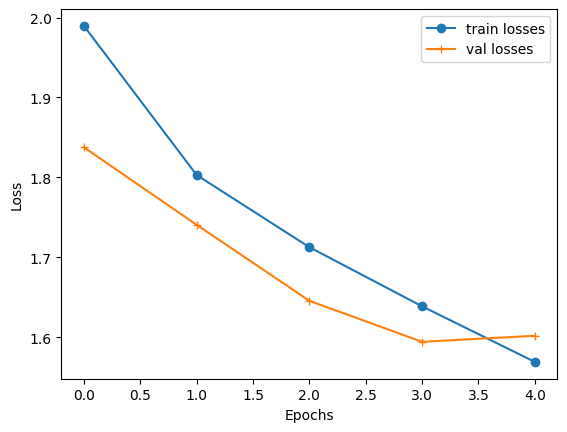

In [91]:
plt.plot(train_losses, marker='o', label='train losses')
plt.plot(val_losses, marker='+', label="val losses")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Task 3.2 - Evaluate the selected model (5 marks)

Reload the **best** checkpoint and evaluate all **1,000 test images** using `eval()` and no gradients. Report top-1 test accuracy. Show a named **10×10 confusion matrix** (rows = true class, columns = predicted class). Identify one frequent observed confusion, or state that none occurred. No assumed accuracy target.

In [100]:
# Task 3.2 - TODO (5 marks)
# Reload checkpoint, evaluate, calculate and display labelled 10×10 confusion matrix.
# You may compute the matrix directly with NumPy/PyTorch.
del model
ckpt = torch.load("best_vit.pt", map_location=DEVICE, weights_only=True)
model = TinyViT().to(DEVICE)
model.load_state_dict(ckpt["model"])

<All keys matched successfully>

In [101]:
evaluate(model, test_loader, criterion)

evaluating: 100%|██████████| 8/8 [00:00<00:00, 189.49it/s]


1.6247320026159286

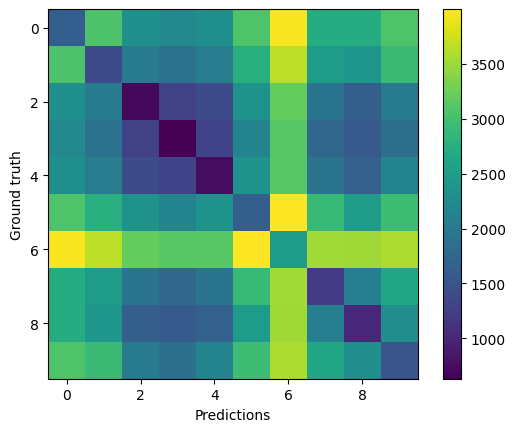

In [167]:
def evaluate_results(model, loader):
    model.eval()
    device = next(model.parameters()).device
    conf_matrix = np.zeros((NUM_CLASSES, NUM_CLASSES)) # [GROUND TRUTH, ACTUAL PRED]
    for imgs, labels in loader:
        imgs = imgs.to(device)
        logits = model(imgs)
        preds = logits.argmax(-1).cpu().numpy()
        labels = labels.numpy()
        # print(preds == labels)
        for l in labels:
            for p in preds:
                if l != p:
                    conf_matrix[l][p] += 1
                    conf_matrix[p][l] += 1
                else:
                    conf_matrix[l][l] += 1
        # print(conf_matrix)
    return conf_matrix

conf_mat = evaluate_results(model, test_loader)
plt.imshow(conf_mat)
# plt.axis("off")
plt.xlabel("Predictions")
plt.ylabel("Ground truth")
plt.colorbar()
plt.show()

In [168]:
accs = [conf_mat[i][i] / 100.0 for i in range(NUM_CLASSES)]
print(accs)

[16.4, 13.99, 7.1, 6.33, 7.41, 16.52, 24.79, 12.25, 10.08, 15.22]


In [170]:
class_names[5], class_names[6]

('dog', 'frog')

**Task 3.2 observation - frequent confusion (based on your own matrix):**

Most confused classes are classes 5 (dog) and 6 (frog).

### Task 3.3 - Convert predictions into textual evidence (4 marks)

Implement `build_evidence(logits, class_names)` to apply softmax, take the two highest-scoring classes, and return **only** class names, scores rounded to 3 decimals, and the fixed uncertainty flag:

\[
\mathrm{uncertain}=(p_{\max}<0.50).
\]

Example format: `top1=cat; score1=0.420; top2=dog; score2=0.310; uncertain=true`.

Demonstrate on the **first five test images in original array order**; use the same five in Question 4. Do **not** input true labels, filenames, or test accuracy into this function or Qwen. These scores are not calibrated correctness probabilities, and two classes are alternatives-not evidence that both objects appear.

In [132]:
_x = torch.tensor([[1.0, 2.0, 3.0], [2.0, 2.0, 2.0]])
torch.softmax(_x, dim=1)

tensor([[0.0900, 0.2447, 0.6652],
        [0.3333, 0.3333, 0.3333]])

In [154]:
# Task 3.3 - TODO (4 marks)
def build_evidence(logits, class_names):
    # TODO: predicted top-2 classes, scores, uncertain flag; use logits only.
    # raise NotImplementedError("Implement build_evidence")
    # b, 10
    probs = torch.softmax(logits, dim=-1)
    max1 = None; max2 = None
    max_val = -float('inf'); max2_val = -float('inf')
    for i in range(NUM_CLASSES):
        if (probs[i] > max_val):
            if max1 is None:
                max1 = i
                max_val = probs[i]
            else:
                max2 = max1
                max2_val = max_val
                max1 = i
                max_val = probs[i]
        elif probs[i] > max2_val:
            max2 = i
            max2_val = probs[i]
    uncertain = max_val < 0.5
    return f"top1={class_names[max1]}; score={max_val:.4f}; top2={class_names[max2]}; score={max2_val:.4f}; uncertain={uncertain}"

# TODO: run best ViT on the first five test samples (without shuffling), save their evidence.

In [149]:
_imgs, _labels = next(iter(test_loader))
print(_imgs.shape)

torch.Size([128, 3, 32, 32])


In [150]:
_imgs = _imgs[:5]
print(_imgs.shape)

torch.Size([5, 3, 32, 32])


In [151]:
_imgs = _imgs.to(DEVICE)
_logits = model(_imgs)
print(_logits.shape)

torch.Size([5, 10])


In [155]:
_logits = _logits.cpu()
evidences = []
for i in range(5):
    evidences.append(build_evidence(_logits[i], class_names=class_names))
    print(evidences[-1])

top1=truck; score=0.5418; top2=airplane; score=0.1563; uncertain=False
top1=airplane; score=0.7796; top2=ship; score=0.1376; uncertain=False
top1=automobile; score=0.2858; top2=truck; score=0.1860; uncertain=True
top1=cat; score=0.2319; top2=frog; score=0.1982; uncertain=True
top1=automobile; score=0.4212; top2=truck; score=0.1536; uncertain=True


**Task 3.3 written answer - why ViT features cannot be fed directly to a text-only Qwen model (1-2 sentences):**

> TODO

## Question 4 - Offline Description Generation and Analysis (10 marks)
### Task 4.1 - Load Qwen and generate descriptions (4 marks)

Load the tokenizer and frozen `AutoModelForCausalLM` from `MODEL_PATH` using **`local_files_only=True`**. Use the provided `DEVICE` / `QWEN_DTYPE` settings. Set `eval()`, freeze all model parameters, and generate one description at a time under `torch.inference_mode()`.

Build a **system + user** chat prompt using `tokenizer.apply_chat_template(..., add_generation_prompt=True)`; use Task 3.3 evidence in the user message. Use **`do_sample=False`, `max_new_tokens=40`**, and decode **only newly generated tokens**, omitting special tokens.

Your system instruction must request a **single short sentence** based solely on evidence. If `uncertain=false`, describe top-1 cautiously (e.g. *appears to show*). If `uncertain=true`, explicitly state uncertainty and present both class predictions as **alternatives**. Prohibit actions, colours, counts, backgrounds, and numeric certainty claims. **Use Qwen's actual output; do not replace it with hard-coded sentences.**

In [ ]:
# Task 4.1 - TODO (4 marks)
# The expected local-only configuration is supplied below (not model-loading solution code).
QWEN_LOAD_SETTINGS = {
    "local_files_only": True,
    "dtype": QWEN_DTYPE,  # for newer Transformers; older versions may require torch_dtype
}
GENERATION_SETTINGS = {
    "do_sample": False,
    "max_new_tokens": 40,
}

# TODO: load AutoTokenizer and AutoModelForCausalLM from MODEL_PATH.
# TODO: freeze all Qwen parameters and set eval mode.
# TODO: write system/user messages, apply chat template, generate for the same five samples.
# TODO: decode newly generated tokens only and retain actual Qwen output.
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH, **QWEN_LOAD_SETTINGS)
qwen_model = AutoModelForCausalLM.from_pretrained(MODEL_PATH, local_files_only=True)
qwen_model.eval()
for p in qwen_model.parameters():
    p.requires_grad = False

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


In [156]:
system_prompt = """
Based only on the supplied evidence, write only short sentence describing the image.
If uncertain=false, describe the most likely class using cautious wording such as "appears to show",
If uncertain=true, explicitly express uncertainty and present the two classes at alternatives.
Do not invert colours, actions, counts, background details, or numerical claims of certainty without clear evidence.
"""

descriptions = []
for i in range(5):
    evidence = evidences[i]
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": evidence}
    ]
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    model_inputs = tokenizer([text], return_tensors="pt")
    with torch.inference_mode():
        generated_ids = qwen_model.generate(**model_inputs, **GENERATION_SETTINGS)
    
    generated_ids = [output_ids[len(input_ids):] for input_ids, output_ids in zip(model_inputs.input_ids, generated_ids)]
    response = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)[0]
    descriptions.append(response.strip())
    print(f"Image {i} Output: {response.strip()}")

/usr/local/lib/python3.10/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


Image 0 Output: The truck is a vehicle while the airplane is an aircraft.
Image 1 Output: The airplane is more likely than the ship.
Image 2 Output: The images appear to show a combination of vehicles with different scores for each category.
Image 3 Output: The cat is more likely than the frog to win this game.
Image 4 Output: The images appear to show a combination of vehicles with different scores for each category.


### Task 4.2 - Inspect image–evidence–text consistency (4 marks)

For the **same first five test images**, display: image, true class (for display only), top-two predictions/scores, uncertainty flag, and Qwen sentence. Save results to `summaries.csv`.

For each output, manually check: (1) class wording agrees with evidence, (2) uncertainty phrasing follows the flag, (3) no unsupported visual details. Report three counts **out of five**, and explain one observed failure (or explicitly state none and describe a plausible failure). Distinguish classifier errors from generation errors. **BLEU/ROUGE are not required.**

For consistent grading, use these suggested CSV columns:
`test_index,true_class,top1,score1,top2,score2,uncertain,description,class_consistent,uncertainty_consistent,no_unsupported_details`.
This is an output-format suggestion; it does not change the assessment criteria in the PDF.

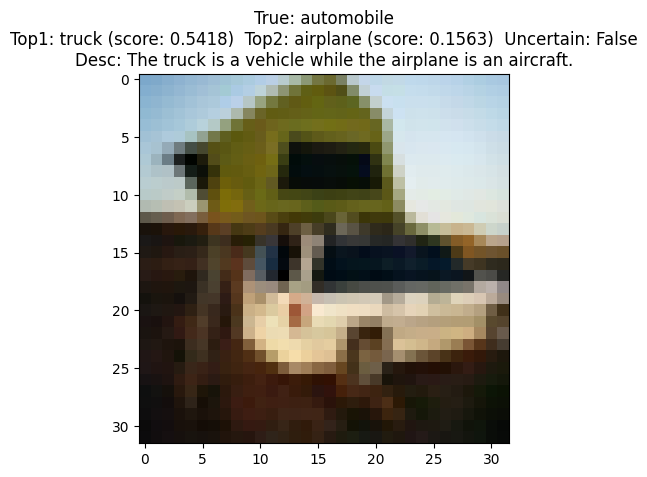

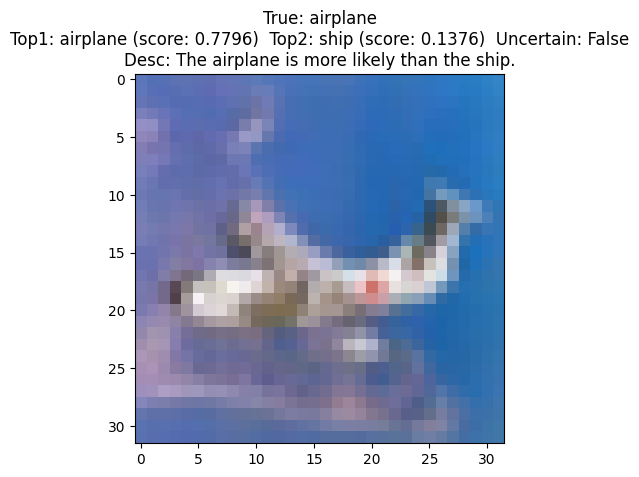

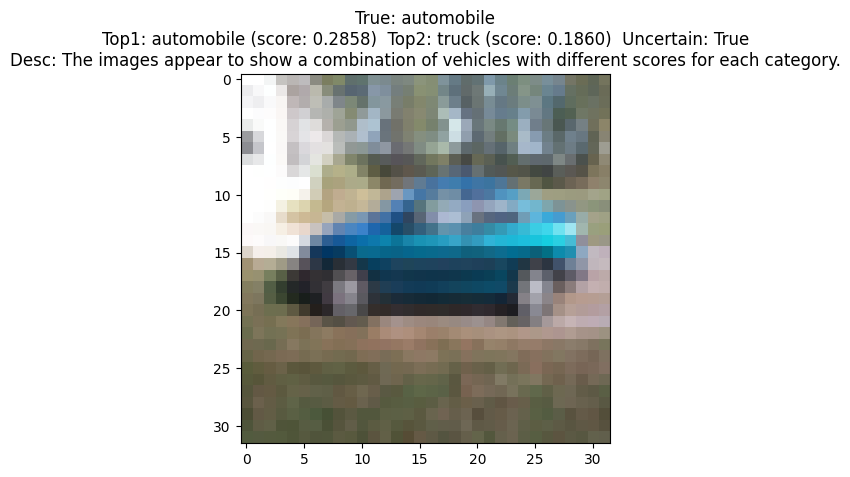

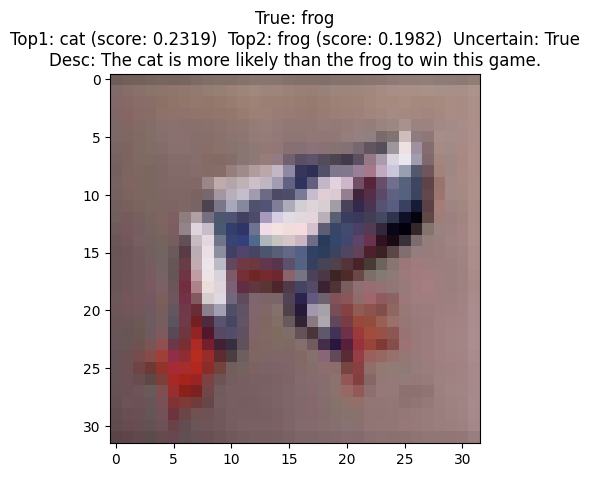

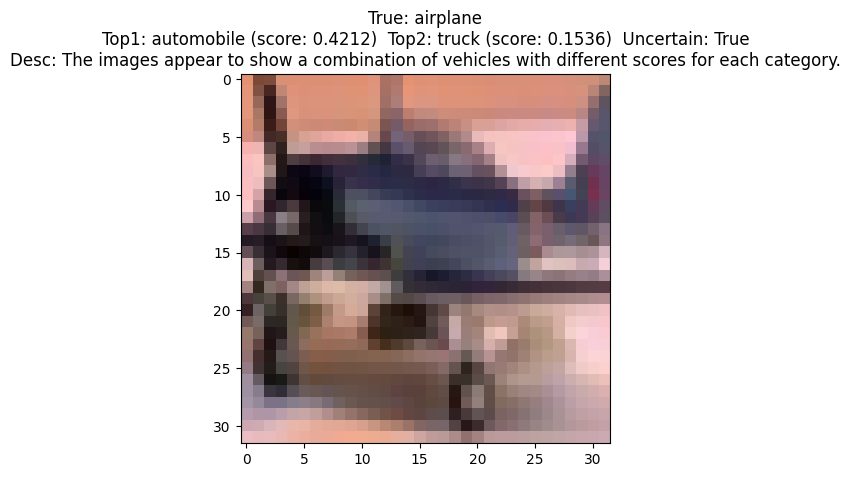

In [166]:
# Task 4.2 - TODO (4 marks)
# Show images, labels (display only), predicted evidence, and actual Qwen sentences.
# Manually review each generated output using the three checks.
# Save results to summaries.csv with suitable columns.
import csv
summaries_data = []
for i in range(5):
    true_class = class_names[y_test[i]]
    ev_parts = evidences[i].split('; ')
    top1 = ev_parts[0].split('=')[1]
    score1 = ev_parts[1].split('=')[1]
    top2 = ev_parts[2].split('=')[1]
    score2 = ev_parts[3].split('=')[1]
    uncertain = ev_parts[4].split('=')[1]

    desc = descriptions[i]
    class_consistent = True
    uncertainty_consistent = True
    no_unsupported_details = True
    summaries_data.append([
        i, true_class, top1, score1, top2, score2, uncertain, desc, class_consistent, uncertainty_consistent, no_unsupported_details
    ])
    img = x_test[i]
    plt.imshow(img)
    plt.title(f"True: {true_class}\nTop1: {top1} (score: {score1})  Top2: {top2} (score: {score2})  Uncertain: {uncertain}\nDesc: {desc}")
    plt.show()

with open('summaries.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow([
        'test_index',
        'true_class',
        'top1',
        'score1',
        'top2',
        'score2',
        'uncertain',
        'description',
        'class_consistent',
        'uncertainty_consistent',
        'no_unsupported_details'
    ])
    writer.writerows(summaries_data)

**Task 4.2 - manual analysis:**

- Class wording consistent with evidence: **TODO / 5**
- Uncertainty rule followed: **TODO / 5**
- No unsupported visual detail: **TODO / 5**

**Observed failure or plausible failure; classifier error vs language-generation error:**

> TODO

### Task 4.3 - Explain the limits (2 marks)

In **at most 100 words**, explain (i) why this pipeline produces only category-level descriptions and (ii) what additional visual supervision or trained multimodal components would be needed for descriptions of attributes, relationships, and objects.

**Task 4.3 written response (≤100 words):**

> TODO